# NeverForget AI — cleaned notebook
Duplicate replay training functions and duplicate 500-sample balanced run were removed. The corrected replay collation function is retained. The six-run automatic overwrite loop was removed; the additional-seed loop is opt-in. **Saved outputs are historical and have not been recomputed.** Keep your original notebook and the 18-run CSV files. Running all cells from a fresh runtime still retrains the earlier baseline and replay experiments.


In [1]:
import torch
import torchvision
import numpy as np
import matplotlib.pyplot as plt

print("PyTorch:", torch.__version__)
print("TorchVision:", torchvision.__version__)
print("GPU Available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.11.0+cpu
TorchVision: 0.26.0+cpu
GPU Available: False


In [2]:
from torchvision import datasets, transforms

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

train_dataset = datasets.MNIST(
    root="./datasets",
    train=True,
    download=True,
    transform=transform
)

test_dataset = datasets.MNIST(
    root="./datasets",
    train=False,
    download=True,
    transform=transform
)

print("Training samples:", len(train_dataset))
print("Testing samples:", len(test_dataset))

100%|██████████| 9.91M/9.91M [00:00<00:00, 62.5MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 1.73MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 14.2MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 10.0MB/s]

Training samples: 60000
Testing samples: 10000


In [3]:
import torch
from torch.utils.data import DataLoader, Subset

# Separate MNIST training data into two tasks
task1_indices = [
    i for i, (_, label) in enumerate(train_dataset)
    if label in [0, 1, 2, 3, 4]
]

task2_indices = [
    i for i, (_, label) in enumerate(train_dataset)
    if label in [5, 6, 7, 8, 9]
]

# Create task datasets
task1_train = Subset(train_dataset, task1_indices)
task2_train = Subset(train_dataset, task2_indices)

# Create test task datasets
task1_test_indices = [
    i for i, (_, label) in enumerate(test_dataset)
    if label in [0, 1, 2, 3, 4]
]

task2_test_indices = [
    i for i, (_, label) in enumerate(test_dataset)
    if label in [5, 6, 7, 8, 9]
]

task1_test = Subset(test_dataset, task1_test_indices)
task2_test = Subset(test_dataset, task2_test_indices)

print("Task 1 training samples:", len(task1_train))
print("Task 2 training samples:", len(task2_train))
print("Task 1 testing samples:", len(task1_test))
print("Task 2 testing samples:", len(task2_test))

Task 1 training samples: 30596
Task 2 training samples: 29404
Task 1 testing samples: 5139
Task 2 testing samples: 4861


In [4]:
batch_size = 64

task1_loader = DataLoader(
    task1_train,
    batch_size=batch_size,
    shuffle=True
)

task2_loader = DataLoader(
    task2_train,
    batch_size=batch_size,
    shuffle=True
)

task1_test_loader = DataLoader(
    task1_test,
    batch_size=batch_size,
    shuffle=False
)

task2_test_loader = DataLoader(
    task2_test,
    batch_size=batch_size,
    shuffle=False
)

print("Task 1 batches:", len(task1_loader))
print("Task 2 batches:", len(task2_loader))

Task 1 batches: 479
Task 2 batches: 460


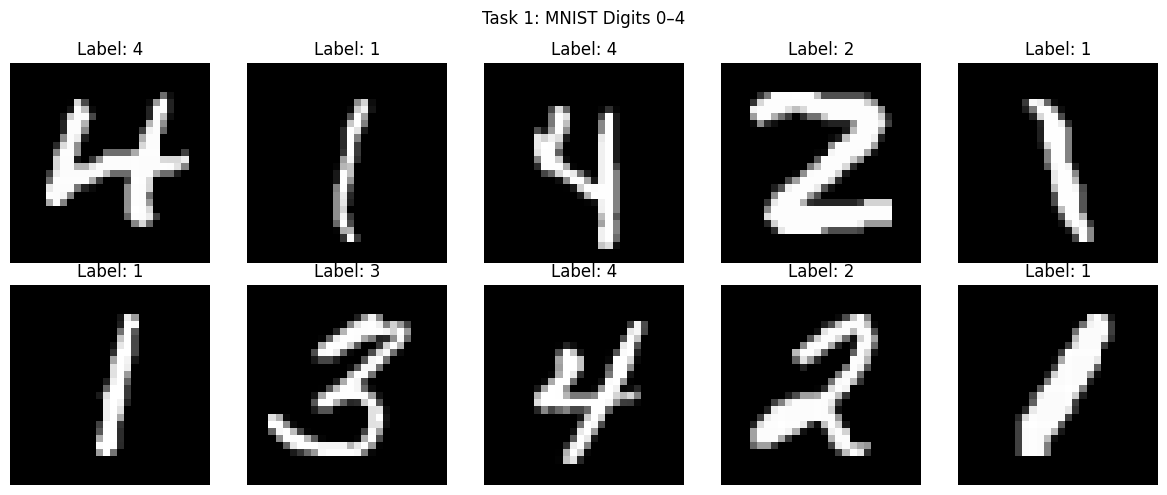

In [5]:
import matplotlib.pyplot as plt

images, labels = next(iter(task1_loader))

fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for i, ax in enumerate(axes.flat):
    ax.imshow(images[i].squeeze(), cmap="gray")
    ax.set_title(f"Label: {labels[i].item()}")
    ax.axis("off")

plt.suptitle("Task 1: MNIST Digits 0–4")
plt.tight_layout()
plt.show()

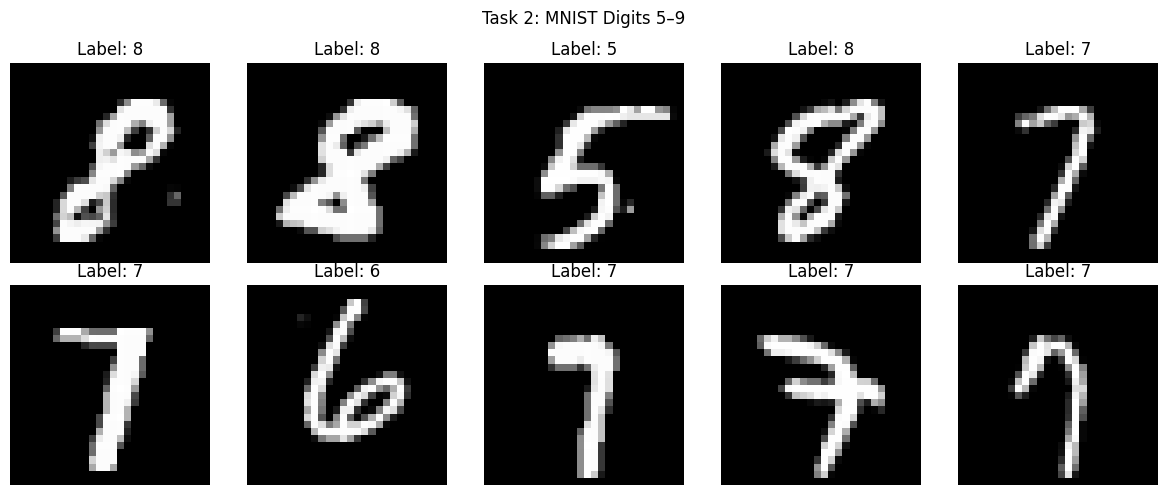

In [6]:
images, labels = next(iter(task2_loader))

fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for i, ax in enumerate(axes.flat):
    ax.imshow(images[i].squeeze(), cmap="gray")
    ax.set_title(f"Label: {labels[i].item()}")
    ax.axis("off")

plt.suptitle("Task 2: MNIST Digits 5–9")
plt.tight_layout()
plt.show()

In [7]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class CNN(nn.Module):
    def __init__(self):
        super(CNN, self).__init__()

        self.conv1 = nn.Conv2d(1, 32, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)

        self.pool = nn.MaxPool2d(2, 2)

        self.fc1 = nn.Linear(64 * 7 * 7, 128)
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))

        x = x.view(x.size(0), -1)

        x = F.relu(self.fc1(x))
        x = self.fc2(x)

        return x

In [8]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = CNN().to(device)

print(model)
print("Training device:", device)

CNN(
  (conv1): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc1): Linear(in_features=3136, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=10, bias=True)
)
Training device: cpu


In [9]:
def train_model(model, train_loader, epochs=5):

    criterion = nn.CrossEntropyLoss()

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=0.001
    )

    for epoch in range(epochs):

        model.train()
        running_loss = 0.0

        for images, labels in train_loader:

            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            outputs = model(images)
            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

            running_loss += loss.item()

        avg_loss = running_loss / len(train_loader)

        print(
            f"Epoch [{epoch+1}/{epochs}], "
            f"Loss: {avg_loss:.4f}"
        )

    return model

In [10]:
def evaluate_model(model, test_loader):

    model.eval()
    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in test_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            predictions = torch.argmax(outputs, dim=1)

            total += labels.size(0)
            correct += (predictions == labels).sum().item()

    accuracy = 100 * correct / total

    return accuracy

In [11]:
print("Training on Task 1: Digits 0–4")

model = train_model(
    model,
    task1_loader,
    epochs=5
)

task1_accuracy_after_task1 = evaluate_model(
    model,
    task1_test_loader
)

print(
    f"Task 1 Accuracy: "
    f"{task1_accuracy_after_task1:.2f}%"
)

Training on Task 1: Digits 0–4
Epoch [1/5], Loss: 0.0946
Epoch [2/5], Loss: 0.0234
Epoch [3/5], Loss: 0.0103
Epoch [4/5], Loss: 0.0089
Epoch [5/5], Loss: 0.0063
Task 1 Accuracy: 99.71%


In [12]:
print("Training on Task 2: Digits 5–9")

model = train_model(
    model,
    task2_loader,
    epochs=5
)

task1_accuracy_after_task2 = evaluate_model(
    model,
    task1_test_loader
)

task2_accuracy_after_task2 = evaluate_model(
    model,
    task2_test_loader
)

print("\nFinal Evaluation")

print(
    f"Task 1 Accuracy after Task 2: "
    f"{task1_accuracy_after_task2:.2f}%"
)

print(
    f"Task 2 Accuracy after Task 2: "
    f"{task2_accuracy_after_task2:.2f}%"
)

Training on Task 2: Digits 5–9
Epoch [1/5], Loss: 0.3833
Epoch [2/5], Loss: 0.0258
Epoch [3/5], Loss: 0.0163
Epoch [4/5], Loss: 0.0127
Epoch [5/5], Loss: 0.0083

Final Evaluation
Task 1 Accuracy after Task 2: 0.00%
Task 2 Accuracy after Task 2: 99.20%


In [13]:
forgetting = (
    task1_accuracy_after_task1 -
    task1_accuracy_after_task2
)

print(f"Catastrophic Forgetting: {forgetting:.2f} percentage points")

Catastrophic Forgetting: 99.71 percentage points


In [14]:
import pandas as pd

results = pd.DataFrame([{
    "Method": "Standard Fine-Tuning",
    "Task1_Initial_Accuracy": task1_accuracy_after_task1,
    "Task1_Final_Accuracy": task1_accuracy_after_task2,
    "Task2_Final_Accuracy": task2_accuracy_after_task2,
    "Forgetting": forgetting
}])

results.to_csv(
    "baseline_results.csv",
    index=False
)

results

,Method,Task1_Initial_Accuracy,Task1_Final_Accuracy,Task2_Final_Accuracy,Forgetting
0,Standard Fine-Tuning,99.708114,0.0,99.197696,99.708114


In [15]:
torch.save(model.state_dict(), "baseline_cnn.pth")

In [16]:
from torch.utils.data import Subset, DataLoader

TASK_CLASSES = [
    [0, 1],
    [2, 3],
    [4, 5],
    [6, 7],
    [8, 9]
]

def create_task_loaders(dataset, task_classes, batch_size=64):

    task_loaders = []

    for classes in task_classes:

        indices = [
            i for i, (_, label) in enumerate(dataset)
            if label in classes
        ]

        task_dataset = Subset(dataset, indices)

        loader = DataLoader(
            task_dataset,
            batch_size=batch_size,
            shuffle=True
        )

        task_loaders.append(loader)

        print(
            f"Task {len(task_loaders)} | "
            f"Classes: {classes} | "
            f"Samples: {len(task_dataset)}"
        )

    return task_loaders


train_task_loaders = create_task_loaders(
    train_dataset,
    TASK_CLASSES
)

test_task_loaders = create_task_loaders(
    test_dataset,
    TASK_CLASSES
)

Task 1 | Classes: [0, 1] | Samples: 12665
Task 2 | Classes: [2, 3] | Samples: 12089
Task 3 | Classes: [4, 5] | Samples: 11263
Task 4 | Classes: [6, 7] | Samples: 12183
Task 5 | Classes: [8, 9] | Samples: 11800
Task 1 | Classes: [0, 1] | Samples: 2115
Task 2 | Classes: [2, 3] | Samples: 2042
Task 3 | Classes: [4, 5] | Samples: 1874
Task 4 | Classes: [6, 7] | Samples: 1986
Task 5 | Classes: [8, 9] | Samples: 1983


In [17]:
def evaluate_all_tasks(model, test_loaders):

    accuracies = []

    for task_id, loader in enumerate(test_loaders):

        accuracy = evaluate_model(model, loader)

        accuracies.append(accuracy)

        print(
            f"Task {task_id + 1} Accuracy: "
            f"{accuracy:.2f}%"
        )

    return accuracies

In [18]:
import copy

baseline_model = CNN().to(device)

accuracy_matrix = []

for task_id, train_loader in enumerate(train_task_loaders):

    print(f"\n========== TASK {task_id + 1} ==========")

    baseline_model = train_model(
        baseline_model,
        train_loader,
        epochs=5
    )

    current_accuracies = evaluate_all_tasks(
        baseline_model,
        test_task_loaders[:task_id + 1]
    )

    accuracy_matrix.append(current_accuracies)

print("\nBaseline experiment completed!")


========== TASK 1 ==========
Epoch [1/5], Loss: 0.0345
Epoch [2/5], Loss: 0.0042
Epoch [3/5], Loss: 0.0013
Epoch [4/5], Loss: 0.0005
Epoch [5/5], Loss: 0.0005
Task 1 Accuracy: 100.00%

========== TASK 2 ==========
Epoch [1/5], Loss: 0.4240
Epoch [2/5], Loss: 0.0234
Epoch [3/5], Loss: 0.0154
Epoch [4/5], Loss: 0.0103
Epoch [5/5], Loss: 0.0056
Task 1 Accuracy: 0.00%
Task 2 Accuracy: 99.76%

========== TASK 3 ==========
Epoch [1/5], Loss: 0.8361
Epoch [2/5], Loss: 0.0055
Epoch [3/5], Loss: 0.0033
Epoch [4/5], Loss: 0.0024
Epoch [5/5], Loss: 0.0013
Task 1 Accuracy: 0.00%
Task 2 Accuracy: 0.00%
Task 3 Accuracy: 100.00%

========== TASK 4 ==========
Epoch [1/5], Loss: 0.8217
Epoch [2/5], Loss: 0.0033
Epoch [3/5], Loss: 0.0014
Epoch [4/5], Loss: 0.0008
Epoch [5/5], Loss: 0.0006
Task 1 Accuracy: 0.00%
Task 2 Accuracy: 0.00%
Task 3 Accuracy: 0.00%
Task 4 Accuracy: 99.95%

========== TASK 5 ==========
Epoch [1/5], Loss: 1.6862
Epoch [2/5], Loss: 0.0395
Epoch [3/5], Loss: 0.0257
Epoch [4/5], Los

In [19]:
import pandas as pd
import numpy as np

accuracy_df = pd.DataFrame(
    accuracy_matrix,
    columns=[f"Task {i+1}" for i in range(5)],
    index=[f"After Task {i+1}" for i in range(5)]
)

print(accuracy_df.round(2))

              Task 1  Task 2  Task 3  Task 4  Task 5
After Task 1   100.0     NaN     NaN     NaN     NaN
After Task 2     0.0   99.76     NaN     NaN     NaN
After Task 3     0.0    0.00   100.0     NaN     NaN
After Task 4     0.0    0.00     0.0   99.95     NaN
After Task 5     0.0    0.00     0.0    0.00   99.24


In [20]:
def calculate_average_forgetting(accuracy_matrix):

    matrix = np.full((5, 5), np.nan)

    for i, row in enumerate(accuracy_matrix):
        matrix[i, :len(row)] = row

    forgetting_values = []

    for task_id in range(4):

        previous_best = np.max(
            matrix[task_id:, task_id]
        )

        final_accuracy = matrix[4, task_id]

        forgetting = previous_best - final_accuracy

        forgetting_values.append(forgetting)

    return np.mean(forgetting_values), forgetting_values


avg_forgetting, task_forgetting = calculate_average_forgetting(
    accuracy_matrix
)

print("Average Forgetting:", round(avg_forgetting, 2))

for i, value in enumerate(task_forgetting):
    print(f"Task {i+1} Forgetting: {value:.2f}")

Average Forgetting: 99.93
Task 1 Forgetting: 100.00
Task 2 Forgetting: 99.76
Task 3 Forgetting: 100.00
Task 4 Forgetting: 99.95


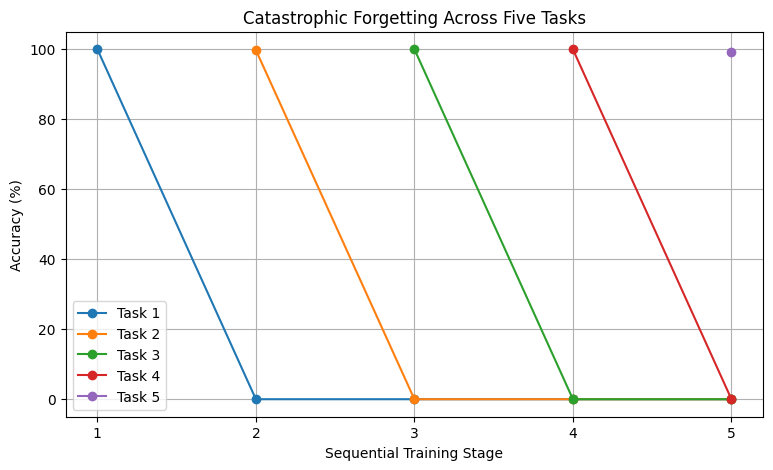

In [21]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

for task_id in range(5):

    values = [
        row[task_id]
        for row in accuracy_matrix
        if len(row) > task_id
    ]

    stages = range(task_id + 1, 6)

    plt.plot(
        stages,
        values,
        marker="o",
        label=f"Task {task_id + 1}"
    )

plt.xlabel("Sequential Training Stage")
plt.ylabel("Accuracy (%)")
plt.title("Catastrophic Forgetting Across Five Tasks")
plt.xticks(range(1, 6))
plt.legend()
plt.grid(True)
plt.show()

In [22]:
accuracy_df.to_csv(
    "five_task_baseline_accuracy.csv"
)

torch.save(
    baseline_model.state_dict(),
    "five_task_baseline_model.pth"
)

print("Five-task baseline saved successfully!")

Five-task baseline saved successfully!


In [23]:
import copy
import torch
import torch.nn as nn

def calculate_fisher(model, data_loader, device):

    model.eval()

    fisher = {
        name: torch.zeros_like(parameter)
        for name, parameter in model.named_parameters()
        if parameter.requires_grad
    }

    criterion = nn.CrossEntropyLoss()

    number_of_batches = 0

    for images, labels in data_loader:

        images = images.to(device)
        labels = labels.to(device)

        model.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()

        for name, parameter in model.named_parameters():
            if parameter.requires_grad and parameter.grad is not None:
                fisher[name] += parameter.grad.detach() ** 2

        number_of_batches += 1

    for name in fisher:
        fisher[name] /= max(number_of_batches, 1)

    return fisher

In [24]:
def save_ewc_task_information(model, fisher):

    previous_parameters = {
        name: parameter.detach().clone()
        for name, parameter in model.named_parameters()
        if parameter.requires_grad
    }

    previous_fisher = {
        name: value.detach().clone()
        for name, value in fisher.items()
    }

    return {
        "parameters": previous_parameters,
        "fisher": previous_fisher
    }

In [25]:
def calculate_ewc_penalty(model, previous_tasks, device):

    penalty = torch.zeros((), device=device)

    for previous_task in previous_tasks:

        for name, parameter in model.named_parameters():

            if not parameter.requires_grad:
                continue

            old_parameter = previous_task["parameters"][name]
            fisher_value = previous_task["fisher"][name]

            penalty += (
                fisher_value *
                (parameter - old_parameter) ** 2
            ).sum()

    return penalty

In [26]:
def train_ewc(
    model,
    train_loader,
    previous_tasks,
    device,
    epochs=5,
    ewc_lambda=1000
):

    criterion = nn.CrossEntropyLoss()

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=0.001
    )

    for epoch in range(epochs):

        model.train()
        total_loss = 0.0

        for images, labels in train_loader:

            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            outputs = model(images)

            classification_loss = criterion(outputs, labels)

            ewc_loss = calculate_ewc_penalty(
                model,
                previous_tasks,
                device
            )

            total = classification_loss + (
                ewc_lambda / 2
            ) * ewc_loss

            total.backward()
            optimizer.step()

            total_loss += total.item()

        print(
            f"Epoch [{epoch+1}/{epochs}], "
            f"Loss: {total_loss / len(train_loader):.4f}"
        )

    return model

In [27]:
ewc_model = CNN().to(device)

previous_tasks = []
ewc_accuracy_matrix = []

for task_id, train_loader in enumerate(train_task_loaders):

    print(f"\n========== EWC TASK {task_id + 1} ==========")

    # Train using EWC protection from previous tasks
    ewc_model = train_ewc(
        model=ewc_model,
        train_loader=train_loader,
        previous_tasks=previous_tasks,
        device=device,
        epochs=5,
        ewc_lambda=1000
    )

    # Evaluate all tasks learned so far
    current_accuracies = evaluate_all_tasks(
        ewc_model,
        test_task_loaders[:task_id + 1]
    )

    ewc_accuracy_matrix.append(current_accuracies)

    # Estimate parameter importance for the current task
    fisher = calculate_fisher(
        ewc_model,
        train_loader,
        device
    )

    # Store the current task's knowledge
    task_information = save_ewc_task_information(
        ewc_model,
        fisher
    )

    previous_tasks.append(task_information)

print("\nEWC experiment completed!")


========== EWC TASK 1 ==========
Epoch [1/5], Loss: 0.0402
Epoch [2/5], Loss: 0.0036
Epoch [3/5], Loss: 0.0017
Epoch [4/5], Loss: 0.0017
Epoch [5/5], Loss: 0.0008
Task 1 Accuracy: 99.91%

========== EWC TASK 2 ==========
Epoch [1/5], Loss: 0.5202
Epoch [2/5], Loss: 0.0231
Epoch [3/5], Loss: 0.0136
Epoch [4/5], Loss: 0.0096
Epoch [5/5], Loss: 0.0078
Task 1 Accuracy: 0.00%
Task 2 Accuracy: 99.80%

========== EWC TASK 3 ==========
Epoch [1/5], Loss: 0.8616
Epoch [2/5], Loss: 0.0133
Epoch [3/5], Loss: 0.0088
Epoch [4/5], Loss: 0.0061
Epoch [5/5], Loss: 0.0043
Task 1 Accuracy: 0.00%
Task 2 Accuracy: 0.00%
Task 3 Accuracy: 100.00%

========== EWC TASK 4 ==========
Epoch [1/5], Loss: 0.6518
Epoch [2/5], Loss: 0.0082
Epoch [3/5], Loss: 0.0059
Epoch [4/5], Loss: 0.0044
Epoch [5/5], Loss: 0.0036
Task 1 Accuracy: 0.00%
Task 2 Accuracy: 0.00%
Task 3 Accuracy: 0.00%
Task 4 Accuracy: 100.00%

========== EWC TASK 5 ==========
Epoch [1/5], Loss: 1.3020
Epoch [2/5], Loss: 0.0320
Epoch [3/5], Loss: 0.0

In [28]:
ewc_accuracy_df = pd.DataFrame(
    ewc_accuracy_matrix,
    columns=[f"Task {i+1}" for i in range(5)],
    index=[f"After Task {i+1}" for i in range(5)]
)

display(ewc_accuracy_df.round(2))

,Task 1,Task 2,Task 3,Task 4,Task 5
After Task 1,99.91,NaN,NaN,NaN,NaN
After Task 2,0.00,99.8,NaN,NaN,NaN
After Task 3,0.00,0.0,100.0,NaN,NaN
After Task 4,0.00,0.0,0.0,100.0,NaN
After Task 5,0.00,0.0,0.0,0.0,99.34


In [29]:
def calculate_forgetting_from_matrix(accuracy_matrix):

    forgetting_values = []

    for task_id in range(4):

        historical_accuracies = [
            accuracy_matrix[stage][task_id]
            for stage in range(task_id, 5)
        ]

        best_accuracy = max(historical_accuracies)
        final_accuracy = accuracy_matrix[4][task_id]

        forgetting = best_accuracy - final_accuracy

        forgetting_values.append(forgetting)

    average_forgetting = sum(forgetting_values) / len(forgetting_values)

    return average_forgetting, forgetting_values


ewc_avg_forgetting, ewc_task_forgetting = (
    calculate_forgetting_from_matrix(ewc_accuracy_matrix)
)

print("EWC Average Forgetting:", round(ewc_avg_forgetting, 2))

for i, value in enumerate(ewc_task_forgetting):
    print(f"Task {i+1} Forgetting: {value:.2f}")

EWC Average Forgetting: 99.93
Task 1 Forgetting: 99.91
Task 2 Forgetting: 99.80
Task 3 Forgetting: 100.00
Task 4 Forgetting: 100.00


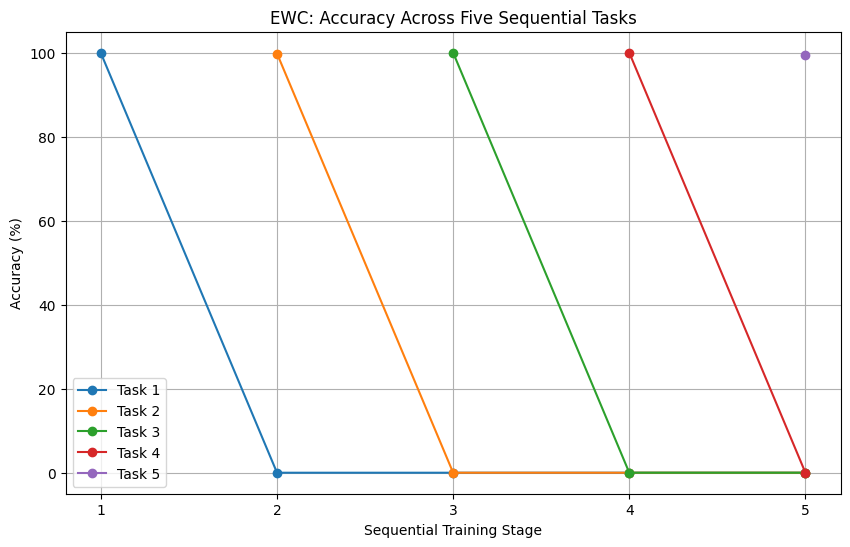

In [30]:
plt.figure(figsize=(10, 6))

for task_id in range(5):

    values = [
        row[task_id]
        for row in ewc_accuracy_matrix
        if len(row) > task_id
    ]

    stages = range(task_id + 1, 6)

    plt.plot(
        stages,
        values,
        marker="o",
        label=f"Task {task_id + 1}"
    )

plt.xlabel("Sequential Training Stage")
plt.ylabel("Accuracy (%)")
plt.title("EWC: Accuracy Across Five Sequential Tasks")
plt.xticks(range(1, 6))
plt.legend()
plt.grid(True)
plt.show()

In [31]:
ewc_accuracy_df.to_csv("ewc_accuracy_results.csv")

torch.save(
    ewc_model.state_dict(),
    "ewc_model.pth"
)

print("EWC results and model saved successfully!")

EWC results and model saved successfully!


In [32]:
baseline_avg_forgetting, baseline_task_forgetting = (
    calculate_forgetting_from_matrix(accuracy_matrix)
)

comparison = pd.DataFrame({
    "Method": ["Fine-Tuning", "EWC"],
    "Average Forgetting": [
        baseline_avg_forgetting,
        ewc_avg_forgetting
    ],
    "Final Average Accuracy": [
        np.mean(accuracy_matrix[4]),
        np.mean(ewc_accuracy_matrix[4])
    ]
})

display(comparison.round(2))

,Method,Average Forgetting,Final Average Accuracy
0,Fine-Tuning,99.93,19.85
1,EWC,99.93,19.87


In [33]:
import random
import torch
from torch.utils.data import TensorDataset, DataLoader, ConcatDataset

class ReplayMemory:

    def __init__(self, capacity=500, strategy="random"):
        self.capacity = capacity
        self.strategy = strategy

        self.memory = []
        self.seen_samples = 0

        self.class_memory = {}

    def add_task(self, loader):

        for images, labels in loader:

            for image, label in zip(images, labels):

                label = int(label.item())
                image = image.detach().cpu().clone()

                if self.strategy == "random":

                    self.seen_samples += 1

                    if len(self.memory) < self.capacity:
                        self.memory.append((image, label))

                    else:
                        position = random.randint(
                            0, self.seen_samples - 1
                        )

                        if position < self.capacity:
                            self.memory[position] = (image, label)

                elif self.strategy == "balanced":

                    if label not in self.class_memory:
                        self.class_memory[label] = []

                    self.class_memory[label].append(image)

        if self.strategy == "balanced":
            self._limit_balanced_memory()

    def _limit_balanced_memory(self):

        classes = list(self.class_memory.keys())

        if not classes:
            return

        samples_per_class = max(
            1, self.capacity // len(classes)
        )

        for label in classes:

            samples = self.class_memory[label]

            if len(samples) > samples_per_class:
                self.class_memory[label] = random.sample(
                    samples, samples_per_class
                )

    def get_data(self):

        if self.strategy == "random":

            if not self.memory:
                return None, None

            images = torch.stack(
                [item[0] for item in self.memory]
            )

            labels = torch.tensor(
                [item[1] for item in self.memory],
                dtype=torch.long
            )

        else:

            all_images = []
            all_labels = []

            for label, samples in self.class_memory.items():

                all_images.extend(samples)
                all_labels.extend([label] * len(samples))

            if not all_images:
                return None, None

            images = torch.stack(all_images)

            labels = torch.tensor(
                all_labels,
                dtype=torch.long
            )

        return images, labels

    def __len__(self):

        if self.strategy == "random":
            return len(self.memory)

        return sum(
            len(samples)
            for samples in self.class_memory.values()
        )

In [42]:
def replay_collate_fn(batch):
    images = torch.stack([item[0] for item in batch])

    labels = torch.tensor(
        [int(item[1]) for item in batch],
        dtype=torch.long
    )

    return images, labels


def train_with_replay(
    model,
    current_loader,
    replay_memory,
    device,
    epochs=5
):

    criterion = nn.CrossEntropyLoss()

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=0.001
    )

    replay_images, replay_labels = replay_memory.get_data()

    if replay_images is not None:

        replay_dataset = TensorDataset(
            replay_images,
            replay_labels
        )

        combined_dataset = ConcatDataset([
            current_loader.dataset,
            replay_dataset
        ])

        training_loader = DataLoader(
            combined_dataset,
            batch_size=64,
            shuffle=True,
            collate_fn=replay_collate_fn
        )

    else:
        training_loader = current_loader

    for epoch in range(epochs):

        model.train()
        total_loss = 0

        for images, labels in training_loader:

            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            outputs = model(images)
            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

            total_loss += loss.item()

        print(
            f"Epoch {epoch + 1}/{epochs}, "
            f"Loss: {total_loss / len(training_loader):.4f}"
        )

    return model

In [64]:
assert "replay_collate_fn" in train_with_replay.__code__.co_names

for strategy in ["random", "balanced"]:
    memory = ReplayMemory(capacity=100, strategy=strategy)
    memory.add_task(train_task_loaders[0])

    assert 0 < len(memory) <= 100
    print(strategy, "memory size:", len(memory))

print("Verification successful!")

random memory size: 100
balanced memory size: 100
Verification successful!


In [36]:
print("ReplayMemory methods:")
print([method for method in dir(ReplayMemory) if not method.startswith("__")])

ReplayMemory methods:
['_limit_balanced_memory', 'add_task', 'get_data']


In [43]:
random.seed(42)
torch.manual_seed(42)

random_model = CNN().to(device)

random_memory = ReplayMemory(
    capacity=500,
    strategy="random"
)

random_accuracy_matrix = []

for task_id, train_loader in enumerate(train_task_loaders):

    print(f"\n===== RANDOM REPLAY: TASK {task_id + 1} =====")

    random_model = train_with_replay(
        random_model,
        train_loader,
        random_memory,
        device,
        epochs=5
    )

    current_accuracies = evaluate_all_tasks(
        random_model,
        test_task_loaders[:task_id + 1]
    )

    random_accuracy_matrix.append(current_accuracies)

    random_memory.add_task(train_loader)

    print("Replay memory size:", len(random_memory))

print("Random Replay completed!")


===== RANDOM REPLAY: TASK 1 =====
Epoch 1/5, Loss: 0.0435
Epoch 2/5, Loss: 0.0038
Epoch 3/5, Loss: 0.0025
Epoch 4/5, Loss: 0.0015
Epoch 5/5, Loss: 0.0011
Task 1 Accuracy: 99.95%
Replay memory size: 500

===== RANDOM REPLAY: TASK 2 =====
Epoch 1/5, Loss: 0.5387
Epoch 2/5, Loss: 0.0282
Epoch 3/5, Loss: 0.0162
Epoch 4/5, Loss: 0.0095
Epoch 5/5, Loss: 0.0060
Task 1 Accuracy: 98.06%
Task 2 Accuracy: 99.80%
Replay memory size: 500

===== RANDOM REPLAY: TASK 3 =====
Epoch 1/5, Loss: 0.7211
Epoch 2/5, Loss: 0.0166
Epoch 3/5, Loss: 0.0101
Epoch 4/5, Loss: 0.0056
Epoch 5/5, Loss: 0.0041
Task 1 Accuracy: 97.64%
Task 2 Accuracy: 96.43%
Task 3 Accuracy: 99.89%
Replay memory size: 500

===== RANDOM REPLAY: TASK 4 =====
Epoch 1/5, Loss: 0.7336
Epoch 2/5, Loss: 0.0192
Epoch 3/5, Loss: 0.0103
Epoch 4/5, Loss: 0.0068
Epoch 5/5, Loss: 0.0040
Task 1 Accuracy: 91.91%
Task 2 Accuracy: 89.91%
Task 3 Accuracy: 94.98%
Task 4 Accuracy: 99.80%
Replay memory size: 500

===== RANDOM REPLAY: TASK 5 =====
Epoch 1/5

In [44]:
random_replay_df = pd.DataFrame(
    random_accuracy_matrix,
    columns=[f"Task {i+1}" for i in range(5)],
    index=[f"After Task {i+1}" for i in range(5)]
)

display(random_replay_df.round(2))

random_avg_forgetting, random_task_forgetting = (
    calculate_forgetting_from_matrix(random_accuracy_matrix)
)

print("Random Replay Average Forgetting:",
      round(random_avg_forgetting, 2))

random_replay_df.to_csv("random_replay_accuracy.csv")

torch.save(
    random_model.state_dict(),
    "random_replay_model.pth"
)

print("Random Replay results saved!")

,Task 1,Task 2,Task 3,Task 4,Task 5
After Task 1,99.95,NaN,NaN,NaN,NaN
After Task 2,98.06,99.80,NaN,NaN,NaN
After Task 3,97.64,96.43,99.89,NaN,NaN
After Task 4,91.91,89.91,94.98,99.80,NaN
After Task 5,90.73,91.58,80.79,89.17,99.45


Random Replay Average Forgetting: 11.79
Random Replay results saved!


In [47]:
random.seed(42)
torch.manual_seed(42)

balanced_model = CNN().to(device)

balanced_memory = ReplayMemory(
    capacity=500,
    strategy="balanced"
)

balanced_accuracy_matrix = []

for task_id, train_loader in enumerate(train_task_loaders):

    print(f"\n===== BALANCED REPLAY: TASK {task_id + 1} =====")

    balanced_model = train_with_replay(
        balanced_model,
        train_loader,
        balanced_memory,
        device,
        epochs=5
    )

    current_accuracies = evaluate_all_tasks(
        balanced_model,
        test_task_loaders[:task_id + 1]
    )

    balanced_accuracy_matrix.append(current_accuracies)

    balanced_memory.add_task(train_loader)

    print("Memory size:", len(balanced_memory))

print("Class-Balanced Replay completed!")


===== BALANCED REPLAY: TASK 1 =====
Epoch 1/5, Loss: 0.0435
Epoch 2/5, Loss: 0.0038
Epoch 3/5, Loss: 0.0025
Epoch 4/5, Loss: 0.0015
Epoch 5/5, Loss: 0.0011
Task 1 Accuracy: 99.95%
Memory size: 500

===== BALANCED REPLAY: TASK 2 =====
Epoch 1/5, Loss: 0.5359
Epoch 2/5, Loss: 0.0267
Epoch 3/5, Loss: 0.0156
Epoch 4/5, Loss: 0.0095
Epoch 5/5, Loss: 0.0069
Task 1 Accuracy: 99.29%
Task 2 Accuracy: 99.61%
Memory size: 500

===== BALANCED REPLAY: TASK 3 =====
Epoch 1/5, Loss: 0.6632
Epoch 2/5, Loss: 0.0183
Epoch 3/5, Loss: 0.0118
Epoch 4/5, Loss: 0.0065
Epoch 5/5, Loss: 0.0048
Task 1 Accuracy: 98.35%
Task 2 Accuracy: 96.91%
Task 3 Accuracy: 99.95%
Memory size: 498

===== BALANCED REPLAY: TASK 4 =====
Epoch 1/5, Loss: 0.8950
Epoch 2/5, Loss: 0.0172
Epoch 3/5, Loss: 0.0085
Epoch 4/5, Loss: 0.0054
Epoch 5/5, Loss: 0.0041
Task 1 Accuracy: 96.93%
Task 2 Accuracy: 96.87%
Task 3 Accuracy: 94.13%
Task 4 Accuracy: 99.60%
Memory size: 496

===== BALANCED REPLAY: TASK 5 =====
Epoch 1/5, Loss: 1.1288
Epo

In [48]:
balanced_replay_df = pd.DataFrame(
    balanced_accuracy_matrix,
    columns=[f"Task {i+1}" for i in range(5)],
    index=[f"After Task {i+1}" for i in range(5)]
)

display(balanced_replay_df.round(2))

balanced_avg_forgetting, balanced_task_forgetting = (
    calculate_forgetting_from_matrix(balanced_accuracy_matrix)
)

print("Balanced Replay Average Forgetting:",
      round(balanced_avg_forgetting, 2))

balanced_replay_df.to_csv("balanced_replay_accuracy.csv")

torch.save(
    balanced_model.state_dict(),
    "balanced_replay_model.pth"
)

print("Balanced Replay results saved!")

,Task 1,Task 2,Task 3,Task 4,Task 5
After Task 1,99.95,NaN,NaN,NaN,NaN
After Task 2,99.29,99.61,NaN,NaN,NaN
After Task 3,98.35,96.91,99.95,NaN,NaN
After Task 4,96.93,96.87,94.13,99.60,NaN
After Task 5,94.47,95.05,82.28,84.19,99.65


Balanced Replay Average Forgetting: 10.78
Balanced Replay results saved!


In [55]:
import pandas as pd
import numpy as np
import os

experiments = {
    "Fine-Tuning": {
        "variable": "accuracy_matrix",
        "files": [
            "five_task_baseline_accuracy.csv"
        ]
    },
    "EWC": {
        "variable": "ewc_accuracy_matrix",
        "files": [
            "ewc_accuracy_results.csv"
        ]
    },
    "Random Replay": {
        "variable": "random_accuracy_matrix",
        "files": [
            "random_replay_accuracy.csv"
        ]
    },
    "Class-Balanced Replay": {
        "variable": "balanced_accuracy_matrix",
        "files": [
            "balanced_replay_accuracy.csv"
        ]
    }
}

for method, config in experiments.items():

    name = config["variable"]
    matrix = globals().get(name)

    if matrix is not None and len(matrix) == 5:
        print(f"{method}: Already available")
        continue

    filename = config["files"][0]

    if os.path.exists(filename):

        df = pd.read_csv(filename, index_col=0)

        if df.shape != (5, 5):
            print(f"{method}: Unexpected CSV shape {df.shape}")
            continue

        restored_matrix = [
            df.iloc[i, :i+1].astype(float).tolist()
            for i in range(5)
        ]

        globals()[name] = restored_matrix

        print(f"{method}: Restored from {filename}")

    else:
        print(f"{method}: CSV file not found")

print("\nRestoration check completed.")

Fine-Tuning: Already available
EWC: Already available
Random Replay: Restored from random_replay_accuracy.csv
Class-Balanced Replay: Already available

Restoration check completed.


In [56]:
import pandas as pd
import numpy as np

results = {
    "Fine-Tuning": accuracy_matrix,
    "EWC": ewc_accuracy_matrix,
    "Random Replay": random_accuracy_matrix,
    "Class-Balanced Replay": balanced_accuracy_matrix
}

comparison_rows = []

for method, matrix in results.items():

    if len(matrix) != 5:
        raise ValueError(
            f"{method} has {len(matrix)} rows; expected 5."
        )

    final_average_accuracy = np.mean(matrix[-1])

    forgetting_values = []

    for task_id in range(4):

        history = [
            matrix[stage][task_id]
            for stage in range(task_id, 5)
        ]

        forgetting_values.append(
            max(history) - matrix[-1][task_id]
        )

    comparison_rows.append({
        "Method": method,
        "Final Average Accuracy (%)": round(
            float(final_average_accuracy), 2
        ),
        "Average Forgetting (percentage points)": round(
            float(np.mean(forgetting_values)), 2
        )
    })

comparison_df = pd.DataFrame(comparison_rows)

display(comparison_df)

comparison_df.to_csv(
    "continual_learning_comparison.csv",
    index=False
)

print("Comparison completed successfully!")

,Method,Final Average Accuracy (%),Average Forgetting (percentage points)
0,Fine-Tuning,19.85,99.93
1,EWC,19.87,99.93
2,Random Replay,90.34,11.79
3,Class-Balanced Replay,91.13,10.78


Comparison completed successfully!


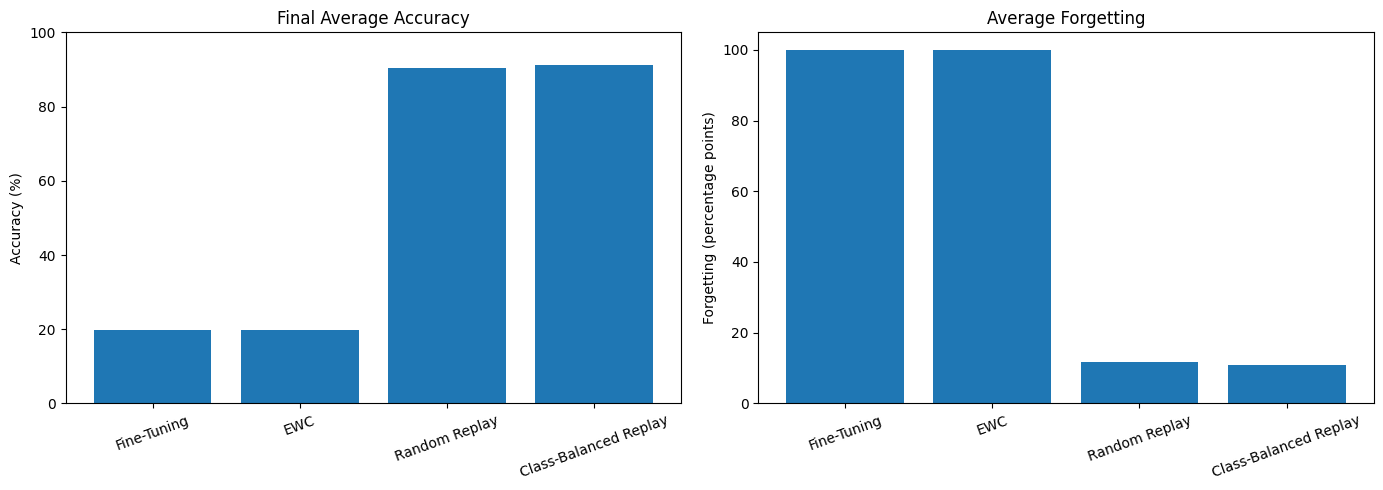

Comparison graph saved successfully!


In [57]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Final average accuracy
axes[0].bar(
    comparison_df["Method"],
    comparison_df["Final Average Accuracy (%)"]
)
axes[0].set_title("Final Average Accuracy")
axes[0].set_ylabel("Accuracy (%)")
axes[0].set_ylim(0, 100)
axes[0].tick_params(axis="x", rotation=20)

# Average forgetting
axes[1].bar(
    comparison_df["Method"],
    comparison_df["Average Forgetting (percentage points)"]
)
axes[1].set_title("Average Forgetting")
axes[1].set_ylabel("Forgetting (percentage points)")
axes[1].tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.savefig(
    "continual_learning_comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("Comparison graph saved successfully!")

In [59]:
# Check ReplayMemory without inspect.getsource()

import torch

print("Checking ReplayMemory...")

for strategy in ["random", "balanced"]:

    memory = ReplayMemory(
        capacity=100,
        strategy=strategy
    )

    print(f"\nStrategy: {strategy}")
    print("Initial memory size:", len(memory))

    # Add data from the first task
    memory.add_task(train_task_loaders[0])

    print("Memory size after Task 1:", len(memory))

    images, labels = memory.get_data()

    if images is not None:
        print("Images shape:", images.shape)
        print("Labels shape:", labels.shape)
        print("Stored classes:", torch.unique(labels).tolist())
    else:
        print("No data stored")

print("\nReplayMemory verification completed!")

Checking ReplayMemory...

Strategy: random
Initial memory size: 0
Memory size after Task 1: 100
Images shape: torch.Size([100, 1, 28, 28])
Labels shape: torch.Size([100])
Stored classes: [0, 1]

Strategy: balanced
Initial memory size: 0
Memory size after Task 1: 100
Images shape: torch.Size([100, 1, 28, 28])
Labels shape: torch.Size([100])
Stored classes: [0, 1]

ReplayMemory verification completed!


In [ ]:
import random
import time
import numpy as np
import pandas as pd
import torch

def run_memory_experiment(capacity, strategy, seed=42):

    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    model = CNN().to(device)

    memory = ReplayMemory(
        capacity=capacity,
        strategy=strategy
    )

    accuracy_matrix_run = []
    memory_sizes = []

    start_time = time.perf_counter()

    for task_id, train_loader in enumerate(train_task_loaders):

        print(
            f"\n{strategy.upper()} | "
            f"Capacity {capacity} | "
            f"Task {task_id + 1}/5"
        )

        model = train_with_replay(
            model,
            train_loader,
            memory,
            device,
            epochs=5
        )

        accuracies = evaluate_all_tasks(
            model,
            test_task_loaders[:task_id + 1]
        )

        accuracy_matrix_run.append(accuracies)

        memory.add_task(train_loader)
        memory_sizes.append(len(memory))

        assert len(memory) <= capacity, (
            f"Memory exceeded capacity: {len(memory)} > {capacity}"
        )

    if device.type == "cuda":
        torch.cuda.synchronize()

    training_time = time.perf_counter() - start_time

    final_accuracy = float(
        np.mean(accuracy_matrix_run[-1])
    )

    forgetting = []

    for task_id in range(4):
        history = [
            accuracy_matrix_run[stage][task_id]
            for stage in range(task_id, 5)
        ]

        forgetting.append(
            max(history) - accuracy_matrix_run[-1][task_id]
        )

    average_forgetting = float(np.mean(forgetting))

    return {
        "Strategy": strategy,
        "Capacity": capacity,
        "Seed": seed,
        "Final Accuracy (%)": round(final_accuracy, 2),
        "Average Forgetting (pp)": round(average_forgetting, 2),
        "Final Memory Size": len(memory),
        "Elapsed Time (seconds)": round(training_time, 2),
        "Accuracy Matrix": accuracy_matrix_run,
        "Memory Sizes": memory_sizes
    }


In [61]:
memory_df = pd.read_csv("memory_capacity_results.csv")

display(memory_df)

print("\nBest final accuracy:")
display(
    memory_df.sort_values(
        "Final Accuracy (%)",
        ascending=False
    ).head(1)
)

print("\nLowest forgetting:")
display(
    memory_df.sort_values(
        "Average Forgetting (pp)"
    ).head(1)
)

,Strategy,Capacity,Seed,Final Accuracy (%),Average Forgetting (pp),Final Memory Size,Elapsed Time (seconds)
0,random,100,42,62.79,46.29,100,480.60
1,balanced,100,42,79.30,25.65,100,478.84
2,random,500,42,90.34,11.79,500,482.93
3,balanced,500,42,91.13,10.78,500,494.77
4,random,1000,42,95.66,5.13,1000,499.86
5,balanced,1000,42,93.46,7.96,1000,496.46



Best final accuracy:


,Strategy,Capacity,Seed,Final Accuracy (%),Average Forgetting (pp),Final Memory Size,Elapsed Time (seconds)
4,random,1000,42,95.66,5.13,1000,499.86



Lowest forgetting:


,Strategy,Capacity,Seed,Final Accuracy (%),Average Forgetting (pp),Final Memory Size,Elapsed Time (seconds)
4,random,1000,42,95.66,5.13,1000,499.86


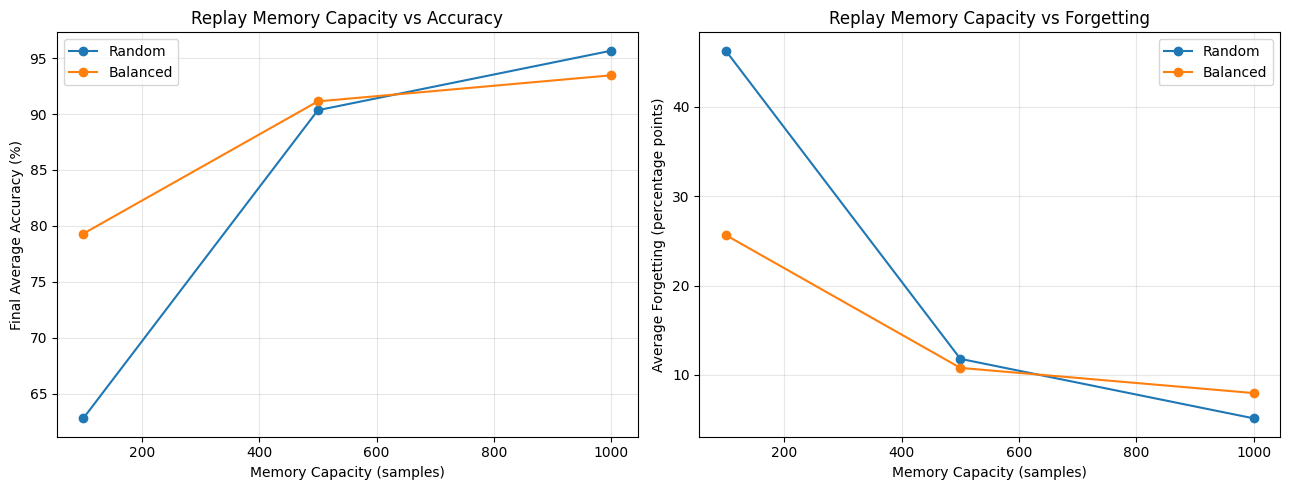

In [62]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for strategy in ["random", "balanced"]:

    data = memory_df[
        memory_df["Strategy"] == strategy
    ].sort_values("Capacity")

    axes[0].plot(
        data["Capacity"],
        data["Final Accuracy (%)"],
        marker="o",
        label=strategy.title()
    )

    axes[1].plot(
        data["Capacity"],
        data["Average Forgetting (pp)"],
        marker="o",
        label=strategy.title()
    )

axes[0].set_title("Replay Memory Capacity vs Accuracy")
axes[0].set_xlabel("Memory Capacity (samples)")
axes[0].set_ylabel("Final Average Accuracy (%)")

axes[1].set_title("Replay Memory Capacity vs Forgetting")
axes[1].set_xlabel("Memory Capacity (samples)")
axes[1].set_ylabel("Average Forgetting (percentage points)")

for ax in axes:
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("memory_capacity_comparison.png", dpi=300)
plt.show()

In [63]:
import torch
import inspect

required_items = [
    "CNN",
    "ReplayMemory",
    "train_with_replay",
    "replay_collate_fn",
    "evaluate_all_tasks",
    "train_task_loaders",
    "test_task_loaders",
    "device"
]

print("Checking required components...\n")

missing = []

for name in required_items:
    if name in globals():
        print(f"PASS: {name}")
    else:
        print(f"MISSING: {name}")
        missing.append(name)

if missing:
    raise RuntimeError(
        "Missing components: " + ", ".join(missing)
    )

assert len(train_task_loaders) == 5
assert len(test_task_loaders) == 5

# Verify replay memory for both strategies
for strategy in ["random", "balanced"]:

    memory = ReplayMemory(
        capacity=100,
        strategy=strategy
    )

    memory.add_task(train_task_loaders[0])

    assert 0 < len(memory) <= 100

    images, labels = memory.get_data()

    assert images is not None
    assert len(images) == len(labels)

    print(
        f"PASS: {strategy} replay, "
        f"stored {len(memory)} samples"
    )

# Check whether the active training function
# references the mixed-label collation helper
assert "replay_collate_fn" in (
    train_with_replay.__code__.co_names
), "Please rerun the corrected train_with_replay function."

print("\nAll preliminary checks passed!")
print("Device:", device)

Checking required components...

PASS: CNN
PASS: ReplayMemory
PASS: train_with_replay
PASS: replay_collate_fn
PASS: evaluate_all_tasks
PASS: train_task_loaders
PASS: test_task_loaders
PASS: device
PASS: random replay, stored 100 samples
PASS: balanced replay, stored 100 samples

All preliminary checks passed!
Device: cpu


In [65]:
print("Checking training function...")

if "replay_collate_fn" in train_with_replay.__code__.co_names:
    print("PASS: Correct training function is active")
else:
    print("FIX NEEDED: Old training function is active")

print("\nChecking experiment results...")

for name in [
    "accuracy_matrix",
    "ewc_accuracy_matrix",
    "random_accuracy_matrix",
    "balanced_accuracy_matrix"
]:
    value = globals().get(name)
    print(name, ":", len(value) if value is not None else "Missing")

Checking training function...
PASS: Correct training function is active

Checking experiment results...
accuracy_matrix : 5
ewc_accuracy_matrix : 5
random_accuracy_matrix : 5
balanced_accuracy_matrix : 5


In [66]:
import pandas as pd
import os

filename = "memory_capacity_results.csv"

if os.path.exists(filename):
    memory_df = pd.read_csv(filename)
    display(memory_df)
    print("SUCCESS: All saved memory experiment results loaded!")
else:
    print("Memory results CSV not found.")

,Strategy,Capacity,Seed,Final Accuracy (%),Average Forgetting (pp),Final Memory Size,Elapsed Time (seconds)
0,random,100,42,62.79,46.29,100,480.60
1,balanced,100,42,79.30,25.65,100,478.84
2,random,500,42,90.34,11.79,500,482.93
3,balanced,500,42,91.13,10.78,500,494.77
4,random,1000,42,95.66,5.13,1000,499.86
5,balanced,1000,42,93.46,7.96,1000,496.46


SUCCESS: All saved memory experiment results loaded!


In [ ]:
import pandas as pd
import os

# Load completed experiments
filename = "memory_capacity_results.csv"
existing_df = pd.read_csv(filename)

# Make sure original results are preserved
required_columns = [
    "Strategy", "Capacity", "Seed",
    "Final Accuracy (%)",
    "Average Forgetting (pp)",
    "Final Memory Size",
    "Elapsed Time (seconds)"
]

assert all(col in existing_df.columns for col in required_columns)

print("Existing experiments:", len(existing_df))

# Optional: set True only when intentionally running missing seeds.
RUN_ADDITIONAL_SEEDS = False

if RUN_ADDITIONAL_SEEDS:
    for seed in [43, 44]:

        for capacity in [100, 500, 1000]:

            for strategy in ["random", "balanced"]:

                # Reload progress to prevent duplicate runs
                existing_df = pd.read_csv(filename)

                already_done = (
                    (existing_df["Seed"] == seed) &
                    (existing_df["Capacity"] == capacity) &
                    (existing_df["Strategy"] == strategy)
                ).any()

                if already_done:
                    print(
                        f"Skipping completed: {strategy}, "
                        f"capacity={capacity}, seed={seed}"
                    )
                    continue

                result = run_memory_experiment(
                    capacity=capacity,
                    strategy=strategy,
                    seed=seed
                )

                # Save only summary fields
                summary = {
                    k: v for k, v in result.items()
                    if k not in ["Accuracy Matrix", "Memory Sizes"]
                }

                updated_df = pd.concat(
                    [existing_df, pd.DataFrame([summary])],
                    ignore_index=True
                )

                updated_df.to_csv(filename, index=False)

                print(
                    f"Saved: {strategy}, "
                    f"capacity={capacity}, seed={seed}"
                )

print("Additional seed experiments are opt-in; existing results are preserved.")

In [70]:
print("Experiment function available:",
      callable(globals().get("run_memory_experiment")))

Experiment function available: True


In [68]:
import pandas as pd

results_df = pd.read_csv("memory_capacity_results.csv")

summary_df = (
    results_df
    .groupby(["Strategy", "Capacity"])
    .agg(
        Runs=("Seed", "nunique"),
        Mean_Accuracy=("Final Accuracy (%)", "mean"),
        Std_Accuracy=("Final Accuracy (%)", "std"),
        Mean_Forgetting=("Average Forgetting (pp)", "mean"),
        Std_Forgetting=("Average Forgetting (pp)", "std"),
        Mean_Time=("Elapsed Time (seconds)", "mean")
    )
    .reset_index()
)

display(summary_df.round(2))

summary_df.to_csv(
    "memory_capacity_multiseed_summary.csv",
    index=False
)

print("Multi-seed summary saved!")

,Strategy,Capacity,Runs,Mean_Accuracy,Std_Accuracy,Mean_Forgetting,Std_Forgetting,Mean_Time
0,balanced,100,3,56.62,20.54,53.98,25.64,477.35
1,balanced,500,3,91.82,1.28,9.85,1.53,487.44
2,balanced,1000,3,92.96,0.47,8.55,0.57,495.05
3,random,100,3,63.66,4.65,45.20,5.81,482.10
4,random,500,3,91.17,0.79,10.71,1.03,484.64
5,random,1000,3,94.66,1.25,6.39,1.57,497.15


Multi-seed summary saved!


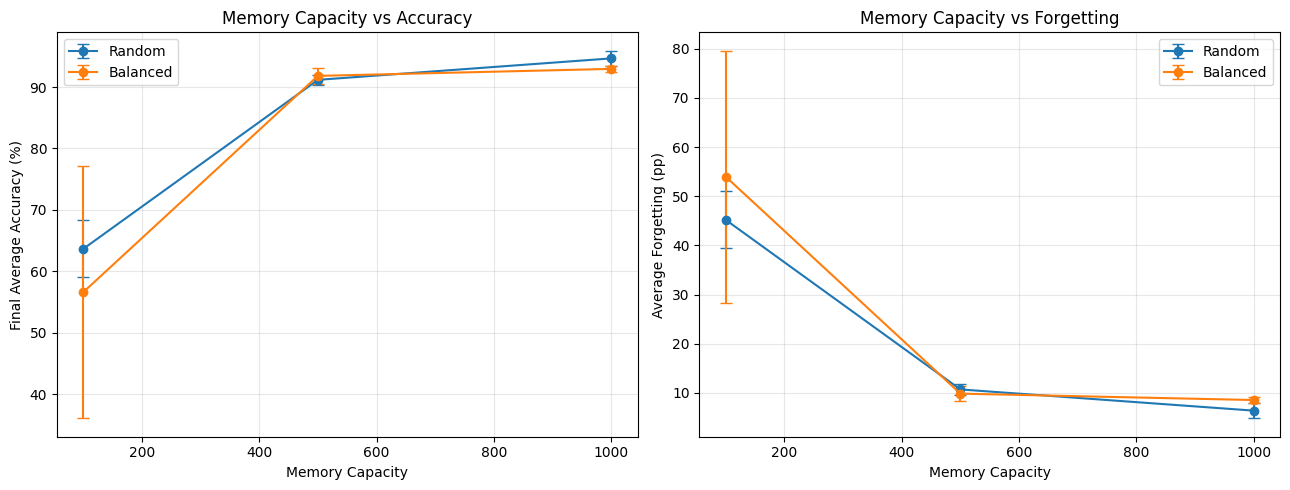

In [69]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for strategy in ["random", "balanced"]:

    data = summary_df[
        summary_df["Strategy"] == strategy
    ].sort_values("Capacity")

    axes[0].errorbar(
        data["Capacity"],
        data["Mean_Accuracy"],
        yerr=data["Std_Accuracy"],
        marker="o",
        capsize=4,
        label=strategy.title()
    )

    axes[1].errorbar(
        data["Capacity"],
        data["Mean_Forgetting"],
        yerr=data["Std_Forgetting"],
        marker="o",
        capsize=4,
        label=strategy.title()
    )

axes[0].set_title("Memory Capacity vs Accuracy")
axes[0].set_xlabel("Memory Capacity")
axes[0].set_ylabel("Final Average Accuracy (%)")

axes[1].set_title("Memory Capacity vs Forgetting")
axes[1].set_xlabel("Memory Capacity")
axes[1].set_ylabel("Average Forgetting (pp)")

for ax in axes:
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(
    "memory_capacity_multiseed_comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [71]:
import pandas as pd

df = pd.read_csv("memory_capacity_results.csv")

print("Completed experiments:", len(df))
print("Expected experiments: 18")

display(df[["Strategy", "Capacity", "Seed"]])

Completed experiments: 18
Expected experiments: 18


,Strategy,Capacity,Seed
0,random,100,42
1,balanced,100,42
2,random,500,42
3,balanced,500,42
4,random,1000,42
5,balanced,1000,42
6,random,100,43
7,balanced,100,43
8,random,500,43
9,balanced,500,43


In [72]:
import pandas as pd

df = pd.read_csv("memory_capacity_results.csv")

# Verify all 18 unique experiments
assert len(df) == 18
assert not df.duplicated(
    ["Strategy", "Capacity", "Seed"]
).any()

summary_df = (
    df.groupby(["Strategy", "Capacity"])
    .agg(
        Runs=("Seed", "nunique"),
        Mean_Accuracy=("Final Accuracy (%)", "mean"),
        Std_Accuracy=("Final Accuracy (%)", "std"),
        Mean_Forgetting=("Average Forgetting (pp)", "mean"),
        Std_Forgetting=("Average Forgetting (pp)", "std"),
        Mean_Time=("Elapsed Time (seconds)", "mean")
    )
    .reset_index()
)

display(summary_df.round(2))

summary_df.to_csv(
    "memory_capacity_multiseed_summary.csv",
    index=False
)

print("Statistical analysis completed!")

,Strategy,Capacity,Runs,Mean_Accuracy,Std_Accuracy,Mean_Forgetting,Std_Forgetting,Mean_Time
0,balanced,100,3,56.62,20.54,53.98,25.64,477.35
1,balanced,500,3,91.82,1.28,9.85,1.53,487.44
2,balanced,1000,3,92.96,0.47,8.55,0.57,495.05
3,random,100,3,63.66,4.65,45.20,5.81,482.10
4,random,500,3,91.17,0.79,10.71,1.03,484.64
5,random,1000,3,94.66,1.25,6.39,1.57,497.15


Statistical analysis completed!


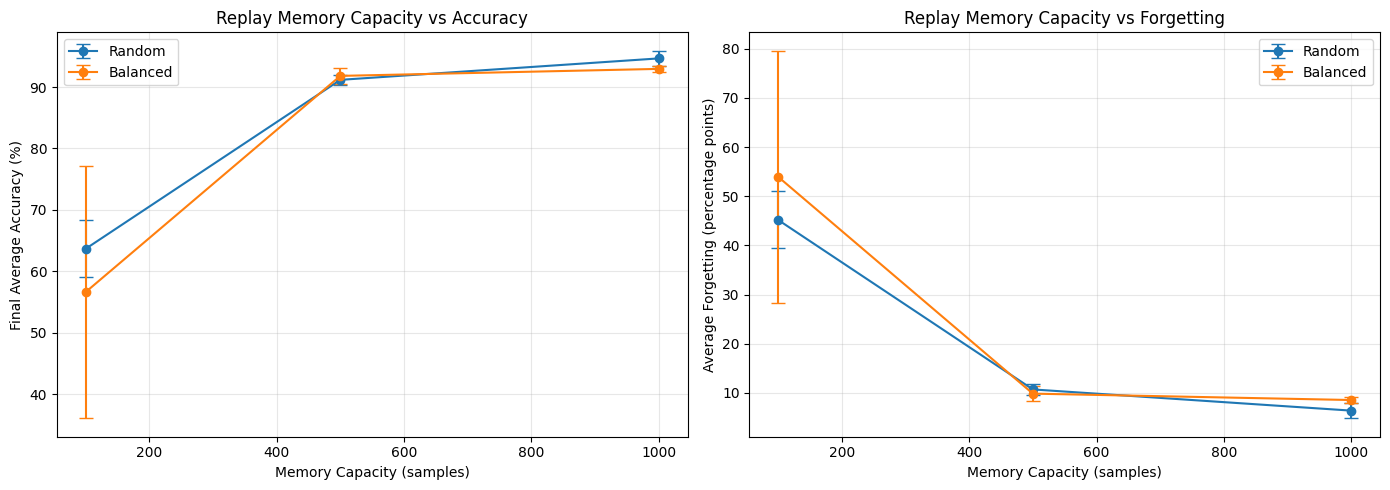

Research graphs saved!


In [73]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for strategy in ["random", "balanced"]:

    data = summary_df[
        summary_df["Strategy"] == strategy
    ].sort_values("Capacity")

    axes[0].errorbar(
        data["Capacity"],
        data["Mean_Accuracy"],
        yerr=data["Std_Accuracy"],
        marker="o",
        capsize=5,
        label=strategy.title()
    )

    axes[1].errorbar(
        data["Capacity"],
        data["Mean_Forgetting"],
        yerr=data["Std_Forgetting"],
        marker="o",
        capsize=5,
        label=strategy.title()
    )

axes[0].set_title("Replay Memory Capacity vs Accuracy")
axes[0].set_xlabel("Memory Capacity (samples)")
axes[0].set_ylabel("Final Average Accuracy (%)")

axes[1].set_title("Replay Memory Capacity vs Forgetting")
axes[1].set_xlabel("Memory Capacity (samples)")
axes[1].set_ylabel("Average Forgetting (percentage points)")

for ax in axes:
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.tight_layout()

plt.savefig(
    "memory_capacity_multiseed_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Research graphs saved!")

In [74]:
import pandas as pd

summary_df = pd.read_csv(
    "memory_capacity_multiseed_summary.csv"
)

display(summary_df.round(2))

,Strategy,Capacity,Runs,Mean_Accuracy,Std_Accuracy,Mean_Forgetting,Std_Forgetting,Mean_Time
0,balanced,100,3,56.62,20.54,53.98,25.64,477.35
1,balanced,500,3,91.82,1.28,9.85,1.53,487.44
2,balanced,1000,3,92.96,0.47,8.55,0.57,495.05
3,random,100,3,63.66,4.65,45.20,5.81,482.10
4,random,500,3,91.17,0.79,10.71,1.03,484.64
5,random,1000,3,94.66,1.25,6.39,1.57,497.15


In [75]:
import pandas as pd
import numpy as np

df = pd.read_csv("memory_capacity_results.csv")

expected = {
    (strategy, capacity, seed)
    for strategy in ["random", "balanced"]
    for capacity in [100, 500, 1000]
    for seed in [42, 43, 44]
}

actual = set(
    zip(df["Strategy"], df["Capacity"], df["Seed"])
)

assert len(df) == 18, "Expected exactly 18 experiments"
assert actual == expected, "Missing or unexpected experiments"
assert not df.isnull().any().any(), "Missing values detected"

assert (
    df["Final Memory Size"] <= df["Capacity"]
).all(), "Memory capacity exceeded"

assert df["Final Accuracy (%)"].between(0, 100).all()
assert df["Average Forgetting (pp)"].between(0, 100).all()

print("PASS: All 18 experiments validated!")

PASS: All 18 experiments validated!


In [76]:
summary_df = pd.read_csv(
    "memory_capacity_multiseed_summary.csv"
)

print("Highest mean accuracy:")
display(
    summary_df.sort_values(
        "Mean_Accuracy",
        ascending=False
    ).head(1).round(2)
)

print("Lowest mean forgetting:")
display(
    summary_df.sort_values(
        "Mean_Forgetting"
    ).head(1).round(2)
)

print("Random vs Balanced comparison:")

comparison = summary_df.pivot(
    index="Capacity",
    columns="Strategy",
    values=["Mean_Accuracy", "Mean_Forgetting"]
)

display(comparison.round(2))

Highest mean accuracy:


,Strategy,Capacity,Runs,Mean_Accuracy,Std_Accuracy,Mean_Forgetting,Std_Forgetting,Mean_Time
5,random,1000,3,94.66,1.25,6.39,1.57,497.15


Lowest mean forgetting:


,Strategy,Capacity,Runs,Mean_Accuracy,Std_Accuracy,Mean_Forgetting,Std_Forgetting,Mean_Time
5,random,1000,3,94.66,1.25,6.39,1.57,497.15


Random vs Balanced comparison:


Mean_Accuracy        Mean_Forgetting       
Strategy      balanced random        balanced random
Capacity                                            
100              56.62  63.66           53.98  45.20
500              91.82  91.17            9.85  10.71
1000             92.96  94.66            8.55   6.39

In [77]:
from google.colab import files

files.download("memory_capacity_results.csv")
files.download("memory_capacity_multiseed_summary.csv")
files.download("memory_capacity_multiseed_comparison.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>